# Modelado de la solución basada en datos
## Modelo de riesgo de default crediticio — Lending Club
**Ciencia de Datos Aplicada · ITBA · Tercer entregable**

Gianluca Giannine Lizarraga · Timoteo Harrington · Lucas Kim

**Qué queremos hacer.** Estimar la probabilidad de que una persona no devuelva un préstamo (la **PD**), usando solo lo que se sabe cuando lo pide. Con esa probabilidad armamos bandas de riesgo y estimamos cuánto se perdería.

**Qué hace este notebook.** En la Entrega 02 dejamos los datos listos. Acá entrenamos y comparamos tres modelos, elegimos uno, lo evaluamos una sola vez con los préstamos de test, armamos las bandas de riesgo y guardamos el modelo para usarlo en la Entrega 04 sin volver a entrenar.

**Contenido**
1. Enfoque y por qué lo elegimos
2. Datos de entrada (y el desempleo por estado)
3. Cómo validamos: un año a la vez
4. Tres modelos y sus hiperparámetros
5. ¿Qué aportan el desempleo y el estado?
6. Evaluación final con test
7. Bandas de riesgo y pérdida esperada
8. Guardar y volver a cargar el modelo
9. Reflexión final

**Palabras que usamos seguido**

| Palabra | Qué significa |
|---|---|
| PD | Probabilidad de default: la chance de que el préstamo no se devuelva |
| Hiperparámetro | Una perilla del modelo que no se aprende de los datos (por ejemplo, cuántos árboles usar). Se elige probando |
| Validación | Probar el modelo con datos que no usó para aprender, para elegir entre opciones sin tocar test |
| ROC-AUC | Si tomamos al azar un préstamo que cayó en default y uno que se pagó, la probabilidad de que el modelo le dé más PD al primero. 0,5 = azar; 1 = perfecto |
| PR-AUC | Qué tan "limpia" es la lista de los más riesgosos: promedio de la proporción de defaults entre los préstamos marcados como riesgosos. Al azar da la tasa de default (~14%) |
| KS | La máxima distancia entre cómo se reparte la PD de los que pagaron y la de los que no. Muy usado en bancos; más alto = mejor |
| Calibración | Si el modelo dice 10%, que de verdad no pague ~10% de esos préstamos |
| Brier | Error promedio de la probabilidad (al cuadrado). Más bajo = mejor |
| Banda de riesgo | Grupo de préstamos con PD parecida (como las notas A-G de Lending Club) |
| Severidad | Qué parte del monto prestado se pierde cuando hay default (51,7%, Entrega 02) |

### Resumen de resultados

| | |
|---|---|
| Enfoque | Clasificación supervisada que devuelve una probabilidad (PD). Tres modelos: regresión logística (base), Random Forest y LightGBM |
| Validación | Por año dentro de train (2013, 2014 y ene-ago 2015), sin tocar test. Test (sep-dic 2015) se usó una sola vez, al final |
| Modelo elegido | **LightGBM** (árboles de 15 hojas, 1.000 árboles, `learning_rate` 0,02): el mejor en los tres años de validación |
| Resultado en test | ROC-AUC **0,704**, KS 0,297, PR-AUC 0,287. La nota de Lending Club (`sub_grade`) logra 0,683 en los mismos préstamos: la superamos usando solo datos de la persona |
| Calibración | Buena forma, pero el nivel queda un punto abajo: PD media 13,9% contra 14,8% de default real en test |
| Desempleo por estado (BLS) | No mejora el modelo (diferencia de AUC: −0,0001) y no explica la suba del default de 2014-2015. Quedó fuera del modelo final |
| Bandas | 7 bandas con cortes definidos en train. En test, el default sube en todas: de 4,2% (banda 1) a 57,4% (banda 7) |
| Pérdida esperada | PD × 51,7%. Acierta en las bandas de bajo riesgo y se queda corta en las de alto riesgo: ahí la severidad real es mayor (Sección 7) |
| Persistencia | `modelos/modelo_pd.joblib` (pipeline completo, 0,7 MB) + `modelos/modelo_pd.json` (cortes, severidad, métricas). Se carga y predice sin reentrenar |

In [1]:
# Solo en Google Colab: clona el repositorio y se ubica en notebooks/. Si todavía no existen
# data/train.parquet y data/test.parquet, baja el dataset de Kaggle (pide el token de la API)
# y ejecuta el notebook 02, que los genera (~10 minutos). Fuera de Colab esta celda no hace nada.
import os, sys

if 'google.colab' in sys.modules:
    REPO = 'https://github.com/lucaskim26/lending-club-riesgo-crediticio'
    DESTINO = '/content/lending-club-riesgo-crediticio'
    if not os.path.exists(DESTINO):
        !git clone -q {REPO} {DESTINO}
    os.chdir(f'{DESTINO}/notebooks')
    !pip install -q lightgbm

    if not os.path.exists('../data/test.parquet'):
        if not os.path.exists('../data/accepted_2007_to_2018Q4.csv.gz'):
            from google.colab import files
            print('Subí tu token de Kaggle (kaggle.json o access_token):')
            subidos = files.upload()
            carpeta_kaggle = os.path.expanduser('~/.kaggle')
            os.makedirs(carpeta_kaggle, exist_ok=True)
            for nombre, contenido in subidos.items():
                destino = 'kaggle.json' if nombre.endswith('.json') else 'access_token'
                ruta = os.path.join(carpeta_kaggle, destino)
                with open(ruta, 'wb') as archivo:
                    archivo.write(contenido)
                os.chmod(ruta, 0o600)
            !pip install -q -U kaggle
            !python ../scripts/download_data.py
        !jupyter nbconvert --to notebook --execute 02_recopilacion_preparacion_datos.ipynb --output /tmp/02_ejecutado.ipynb --ExecutePreprocessor.timeout=3600

In [2]:
import sys
sys.path.insert(0, '..')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve

from src import features as F
from src import modelado as M
from src import evaluacion as E
from src.graficos import aplicar_estilo, guardar, AZUL, NARANJA, AQUA, GRIS, TINTA

aplicar_estilo()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pct = mtick.PercentFormatter(1.0, decimals=0)

## 1. Enfoque y por qué lo elegimos

**Tipo de problema.** Es un problema de **clasificación supervisada**: para cada préstamo de la historia sabemos si se pagó (0) o no (1), y queremos aprender a predecirlo con los datos de la solicitud. Pero no nos interesa el "sí/no": nos interesa la **probabilidad**, porque con ella armamos bandas y calculamos la pérdida esperada (PD × severidad). Por eso:

- Elegimos modelos que devuelven una probabilidad.
- **No usamos accuracy**: un modelo que dice siempre "va a pagar" acierta el 86% y no sirve. Medimos si el modelo **ordena** bien el riesgo (ROC-AUC, PR-AUC, KS) y si sus **probabilidades** son creíbles (calibración, Brier).
- **No rebalanceamos las clases** (no le damos más peso a los defaults): eso mejora poco el orden y distorsiona las probabilidades, que después usamos para calcular pérdidas.

**Los tres modelos**

| Modelo | Cómo funciona, en simple | Por qué lo probamos |
|---|---|---|
| Regresión logística | Suma ponderada de las variables, pasada a una probabilidad. Cada variable empuja la PD para arriba o para abajo | Es el estándar de la industria y fácil de explicar. Es nuestra **línea de base** |
| Random Forest | Muchos árboles de decisión, cada uno entrenado con una parte distinta de los datos; la PD es el promedio de sus votos | Capta relaciones no lineales y combinaciones de variables sin que se las indiquemos |
| LightGBM (*gradient boosting*) | Árboles chicos que se agregan de a uno, cada uno corrigiendo los errores de los anteriores | Suele ser el mejor en datos tabulares como estos |

**Contra qué comparamos.** La nota de Lending Club (`sub_grade`), que es el resultado de su propio modelo de riesgo. Si no la superamos usando solo datos de la persona, nuestro modelo no agrega nada.

**Qué incorporamos de la devolución de la Entrega 02**
1. **Desempleo por estado y mes** (BLS), tomado del mes anterior al préstamo para no usar información del futuro (Sección 2.2 y Sección 5).
2. **Severidad de 2014-2015**: revisamos si la cobranza incompleta la sesga (Sección 7.3).
3. **Validación por año dentro de train**, además del test de 4 meses (Sección 3).

## 2. Datos de entrada

### 2.1 Train y test de la Entrega 02

Cargamos los archivos que guardó el notebook 02. Tienen las 54 variables limpias, **sin** rellenar vacíos ni escalar: esos pasos se ajustan dentro de cada modelo, solo con los datos con los que aprende. También traen la nota de Lending Club (solo para comparar) y la pérdida observada de los defaults (solo para evaluar).

**El default de test no se mira hasta la Sección 6.**

In [3]:
train = pd.read_parquet('../data/train.parquet')
test = pd.read_parquet('../data/test.parquet')

numericas, binarias, categoricas = F.features_modelo()
print(f"Train: {len(train):,} préstamos ({train['fecha_originacion'].min():%b-%Y} a {train['fecha_originacion'].max():%b-%Y})")
print(f"Test:  {len(test):,} préstamos ({test['fecha_originacion'].min():%b-%Y} a {test['fecha_originacion'].max():%b-%Y})")
print(f"Variables: {len(numericas)} numéricas, {len(binarias)} binarias, {len(categoricas)} categóricas")
print(f"Default en train: {train['default'].mean():.1%}")

Train: 511,150 préstamos (Jun-2007 a Aug-2015)
Test:  107,195 préstamos (Sep-2015 a Dec-2015)
Variables: 47 numéricas, 4 binarias, 3 categóricas
Default en train: 13.7%


### 2.2 Desempleo por estado (BLS)

**Por qué.** En la Entrega 02 vimos que el default cambia mucho de un año a otro, y no podíamos separar si era por la **economía** (más desempleo, más gente que no puede pagar) o por el **perfil de los clientes** (Lending Club fue prestando a gente más riesgosa). Si le damos al modelo una medida de la economía, puede aprender las dos cosas por separado.

**Qué usamos.** La **tasa de desempleo mensual de cada estado**, desestacionalizada, del programa *Local Area Unemployment Statistics* del Bureau of Labor Statistics (BLS) de EE.UU. Está guardada en `datos_externos/desempleo_estatal_bls.csv` (50 estados, DC y Puerto Rico, 2006-2016); `scripts/download_desempleo.py` la vuelve a bajar.

**Cómo, sin leakage.** A cada préstamo le asignamos el desempleo de su estado (`addr_state`) en el **mes anterior** al que se dio el préstamo. Así usamos un dato que ya existía cuando se tomó la decisión. Creamos dos variables (`src/modelado.py`, `agregar_macro`):

| Variable | Qué mide |
|---|---|
| `desempleo_estado` | Tasa de desempleo del estado el mes anterior (%) |
| `desempleo_cambio_12m` | Cuánto cambió esa tasa en los 12 meses previos (puntos). Positivo = la economía del estado empeora |

In [4]:
train = M.agregar_macro(train)
test = M.agregar_macro(test)

print('Préstamos sin dato de desempleo:',
      f"train {train['desempleo_estado'].isna().sum()}, test {test['desempleo_estado'].isna().sum()}")
train[M.MACRO].describe().T.round(2)

Préstamos sin dato de desempleo: train 0, test 0


,count,mean,std,min,25%,50%,75%,max
desempleo_estado,511150.0,6.66,1.61,2.6,5.6,6.4,7.5,14.3
desempleo_cambio_12m,511150.0,-0.94,0.75,-3.5,-1.4,-1.0,-0.6,6.4


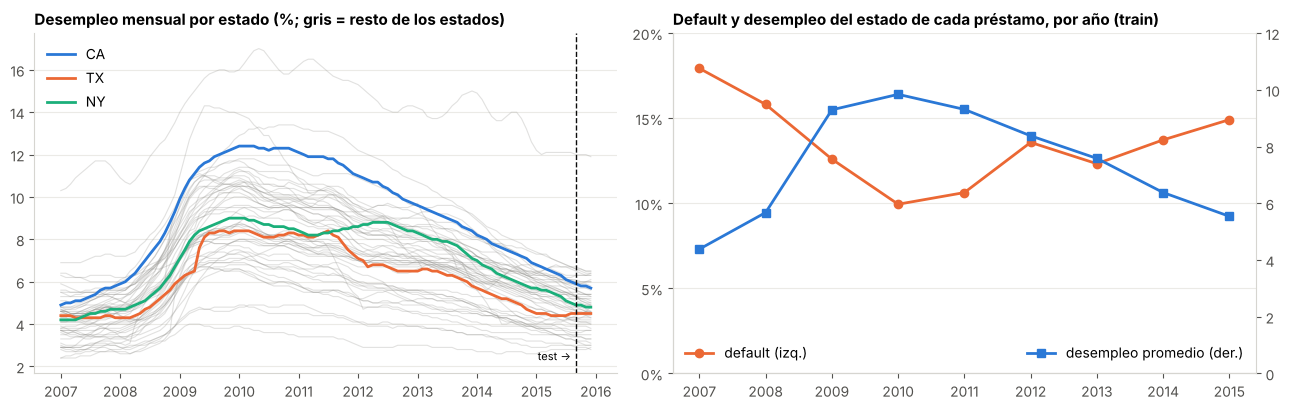

,prestamos,tasa_default,desempleo_promedio
fecha_originacion,,,
2007,251,17.9%,4.4
2008,"1,562",15.8%,5.7
2009,"4,716",12.6%,9.3
2010,"8,466",9.9%,9.8
2011,"14,101",10.6%,9.3
2012,"43,470",13.6%,8.4
2013,"100,422",12.3%,7.6
2014,"162,570",13.7%,6.4
2015,"175,592",14.9%,5.5


In [5]:
desempleo = pd.read_csv('../datos_externos/desempleo_estatal_bls.csv', parse_dates=['mes'])
por_anio = train.groupby(train['fecha_originacion'].dt.year).agg(
    prestamos=('default', 'size'), tasa_default=('default', 'mean'),
    desempleo_promedio=('desempleo_estado', 'mean'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
pivote = desempleo.pivot(index='mes', columns='estado', values='tasa_desempleo')
pivote = pivote.loc['2007-01':'2015-12']
for estado in pivote.columns:
    axes[0].plot(pivote.index, pivote[estado], color=GRIS, alpha=0.25, linewidth=0.8)
for estado, color in [('CA', AZUL), ('TX', NARANJA), ('NY', AQUA)]:
    axes[0].plot(pivote.index, pivote[estado], color=color, label=estado)
axes[0].axvline(pd.Timestamp('2015-09-01'), color=TINTA, linestyle='--', linewidth=1)
axes[0].text(pd.Timestamp('2015-08-01'), 2.3, 'test →', ha='right', fontsize=8)
axes[0].set_title('Desempleo mensual por estado (%; gris = resto de los estados)')
axes[0].legend(loc='upper left')

eje = axes[1]
eje.plot(por_anio.index, por_anio['tasa_default'], marker='o', color=NARANJA, label='default (izq.)')
eje.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
eje.yaxis.set_major_formatter(pct)
eje.set_ylim(0, 0.2)
eje2 = eje.twinx()
eje2.plot(por_anio.index, por_anio['desempleo_promedio'], marker='s', color=AZUL, label='desempleo promedio (der.)')
eje2.set_ylim(0, 12)
eje2.grid(False)
eje2.spines['right'].set_visible(True)
eje.set_title('Default y desempleo del estado de cada préstamo, por año (train)')
eje.legend(loc='lower left')
eje2.legend(loc='lower right')
plt.tight_layout()
guardar(fig, '14_desempleo')
plt.show()
por_anio.style.format({'prestamos': '{:,}', 'tasa_default': '{:.1%}', 'desempleo_promedio': '{:.1f}'})

**Qué muestra.**

- **Izquierda**: el desempleo subió en todos los estados en 2008-2009 (California llegó a 12%) y bajó de a poco hasta 2015. Hay diferencias grandes entre estados en el mismo mes, y eso es lo que el modelo puede aprovechar además del paso del tiempo.
- **Derecha**: el default y el desempleo **se mueven al revés** de lo que uno esperaría. Cuando el desempleo fue máximo (2009-2011), el default fue mínimo (~10%); y cuando el desempleo bajó (2013-2015), el default subió. La explicación es la de la Entrega 02: después de la crisis, Lending Club prestó solo a los mejores perfiles, y después fue aflojando.
- **Consecuencia**: en estos datos, el efecto de la economía está mezclado con el cambio de política de Lending Club, y los dos van en direcciones opuestas. Es una advertencia para la Sección 5: el modelo puede aprender que "más desempleo = menos default", que no es una relación causal.

## 3. Cómo validamos: un año a la vez

Para elegir entre modelos y entre hiperparámetros necesitamos datos que el modelo no haya visto, **sin usar test** (si eligiéramos mirando test, el resultado final sería optimista). Usamos **validación temporal con ventana creciente** dentro de train:

| Corte | Aprende con | Se evalúa con |
|---|---|---|
| 1 | jun-2007 a dic-2012 | 2013 |
| 2 | jun-2007 a dic-2013 | 2014 |
| 3 | jun-2007 a dic-2014 | ene-ago 2015 |

Es como usaríamos el modelo en la realidad: aprende del pasado y predice el año siguiente. Además, como cada corte es un año distinto, vemos si el modelo **funciona parecido en distintos años** (la devolución de la Entrega 02 señaló que el test cubre solo 4 meses). No usamos cortes anteriores a 2013 porque los años 2007-2011 juntos tienen menos de 30 mil préstamos.

Todos los pasos que aprenden de los datos (percentiles para recortar, medianas, escalas, categorías) se ajustan **dentro de cada corte**, solo con la parte de aprendizaje: van dentro de un `Pipeline` de scikit-learn junto con el modelo.

In [6]:
ANIOS_VALIDACION = [2013, 2014, 2015]
cortes = list(M.cortes_temporales(train['fecha_originacion'], ANIOS_VALIDACION))
y_train = train['default']

pd.DataFrame([{
    'año de validación': anio,
    'préstamos para aprender': len(i_apr),
    'préstamos para validar': len(i_val),
    'default en validación': y_train.iloc[i_val].mean(),
} for anio, i_apr, i_val in cortes]).set_index('año de validación').style.format(
    {'préstamos para aprender': '{:,}', 'préstamos para validar': '{:,}', 'default en validación': '{:.1%}'})

,préstamos para aprender,préstamos para validar,default en validación
año de validación,,,
2013,"72,566","100,422",12.3%
2014,"172,988","162,570",13.7%
2015,"335,558","175,592",14.9%


In [7]:
def validar(tipo, params=None, **variante):
    """Entrena en cada corte temporal y devuelve las métricas y las PD de validación."""
    filas, predicciones = [], pd.Series(np.nan, index=train.index)
    for anio, i_apr, i_val in cortes:
        modelo = M.crear_modelo(tipo, params, **variante)
        modelo.fit(train.iloc[i_apr], y_train.iloc[i_apr])
        pd_val = M.predecir_pd(modelo, train.iloc[i_val])
        predicciones.iloc[i_val] = pd_val
        filas.append({'año': anio, **E.metricas_pd(y_train.iloc[i_val], pd_val)})
    return pd.DataFrame(filas).set_index('año'), predicciones

# Referencia: la nota de Lending Club en los mismos préstamos de validación
sub_grade_orden = train['sub_grade'].rank(method='dense')
benchmark_validacion = pd.Series(
    {anio: roc_auc_score(y_train.iloc[i_val], sub_grade_orden.iloc[i_val]) for anio, _, i_val in cortes},
    name='sub_grade (Lending Club)')
benchmark_validacion.round(3).to_frame('ROC-AUC')

,ROC-AUC
2013,0.649
2014,0.660
2015,0.677


La nota de Lending Club ordena un poco mejor cada año (de 0,65 a 0,68): es la vara que tenemos que superar **en cada año**, no solo en promedio.

## 4. Tres modelos y sus hiperparámetros

Para cada modelo probamos unas pocas combinaciones de hiperparámetros y elegimos la que tiene **mejor ROC-AUC promedio en los tres años de validación**. Usamos pocas combinaciones a propósito: con tantos datos, las diferencias entre configuraciones razonables son chicas, y una búsqueda enorme corre el riesgo de elegir por suerte.

En esta etapa todos los modelos usan las mismas 56 variables (las 54 de la Entrega 02 más las 2 de desempleo). Si el desempleo se queda en el modelo final se decide en la Sección 5.

### 4.1 Regresión logística (línea de base)

Usa la preparación completa de la Entrega 02 (`crear_preprocesador`: recorte de extremos, relleno con la mediana, misma escala y categorías a 0/1). El hiperparámetro `C` controla la **regularización**: cuanto más chico, más se "achican" los coeficientes, lo que evita que el modelo se aprenda de memoria particularidades de train.

In [8]:
def buscar(tipo, grilla):
    """Valida cada combinación de la grilla y devuelve la tabla ordenada por AUC promedio."""
    filas, guardadas = [], {}
    for params in grilla:
        inicio = time.time()
        metricas, pd_val = validar(tipo, params)
        clave = ', '.join(f'{k}={v}' for k, v in params.items())
        guardadas[clave] = (params, metricas, pd_val)
        filas.append({'hiperparámetros': clave,
                      **{f'AUC {a}': metricas.loc[a, 'roc_auc'] for a in ANIOS_VALIDACION},
                      'AUC promedio': metricas['roc_auc'].mean(),
                      'segundos': time.time() - inicio})
    tabla = pd.DataFrame(filas).set_index('hiperparámetros').sort_values('AUC promedio', ascending=False)
    mejor = guardadas[tabla.index[0]]
    return tabla, mejor

tabla_logistica, mejor_logistica = buscar('logistica', [{'C': 0.01}, {'C': 0.1}, {'C': 1.0}])
tabla_logistica.round(4)

,AUC 2013,AUC 2014,AUC 2015,AUC promedio,segundos
hiperparámetros,,,,,
C=0.01,0.6643,0.6727,0.6824,0.6731,13.6175
C=0.1,0.6628,0.6725,0.6823,0.6726,12.6117
C=1.0,0.6625,0.6726,0.6823,0.6725,12.4260


La regularización casi no cambia nada (AUC 0,6731 con `C = 0,01` contra 0,6725 con `C = 1`): con 70 mil a 335 mil préstamos para aprender y ~105 columnas, el modelo no llega a sobreajustar. Nos quedamos con `C = 0,01`, el mejor por poco.

### 4.2 Random Forest

Los árboles no necesitan recorte, relleno ni escala: usan los valores tal cual y tratan los vacíos como un valor más. Solo pasamos las categorías a columnas 0/1. Fijamos 200 árboles, cada uno entrenado con un 30% de los préstamos elegido al azar (para que sea rápido y los árboles sean distintos entre sí). Probamos:
- `min_samples_leaf`: cuántos préstamos tiene que haber como mínimo en cada hoja del árbol. Más grande = árboles más simples, que generalizan mejor pero captan menos detalle.
- `max_features`: cuántas variables puede mirar cada división del árbol.

In [9]:
grilla_rf = [{'min_samples_leaf': 50, 'max_features': 'sqrt'},
             {'min_samples_leaf': 100, 'max_features': 'sqrt'},
             {'min_samples_leaf': 50, 'max_features': 0.3}]
tabla_rf, mejor_rf = buscar('random_forest', grilla_rf)
tabla_rf.round(4)

,AUC 2013,AUC 2014,AUC 2015,AUC promedio,segundos
hiperparámetros,,,,,
"min_samples_leaf=50, max_features=sqrt",0.6675,0.6721,0.6817,0.6738,69.4838
"min_samples_leaf=50, max_features=0.3",0.6655,0.6730,0.6822,0.6736,182.6356
"min_samples_leaf=100, max_features=sqrt",0.6651,0.6702,0.6797,0.6717,61.8760


Las tres configuraciones dan casi lo mismo (0,672 a 0,674) y quedan a la par de la logística. Nos quedamos con hojas de al menos 50 préstamos y `max_features = sqrt`, que además es la más rápida de las dos mejores.

### 4.3 LightGBM

Probamos:
- `num_leaves`: tamaño de cada árbol (cantidad de hojas). Árboles chicos captan relaciones simples; grandes, combinaciones más complejas.
- `learning_rate` y `n_estimators`: cuánto corrige cada árbol nuevo y cuántos árboles se agregan. Un `learning_rate` más chico necesita más árboles pero suele generalizar mejor.

El resto queda fijo: cada árbol ve el 80% de los préstamos y el 80% de las variables, y cada hoja necesita al menos 200 préstamos.

In [10]:
grilla_lgbm = [{'num_leaves': 7, 'learning_rate': 0.05, 'n_estimators': 600},
               {'num_leaves': 15, 'learning_rate': 0.05, 'n_estimators': 400},
               {'num_leaves': 31, 'learning_rate': 0.05, 'n_estimators': 400},
               {'num_leaves': 15, 'learning_rate': 0.02, 'n_estimators': 1000},
               {'num_leaves': 31, 'learning_rate': 0.02, 'n_estimators': 1500}]
tabla_lgbm, mejor_lgbm = buscar('lightgbm', grilla_lgbm)
tabla_lgbm.round(4)

,AUC 2013,AUC 2014,AUC 2015,AUC promedio,segundos
hiperparámetros,,,,,
"num_leaves=15, learning_rate=0.02, n_estimators=1000",0.6717,0.6845,0.6948,0.6837,57.6445
"num_leaves=15, learning_rate=0.05, n_estimators=400",0.6698,0.6835,0.6943,0.6825,26.9826
"num_leaves=7, learning_rate=0.05, n_estimators=600",0.6707,0.6828,0.6929,0.6821,30.3537
"num_leaves=31, learning_rate=0.02, n_estimators=1500",0.6633,0.6844,0.6965,0.6814,116.9665
"num_leaves=31, learning_rate=0.05, n_estimators=400",0.6636,0.6831,0.6954,0.6807,32.4428


- Las mejores configuraciones usan **árboles chicos** (15 hojas). Los de 31 hojas andan igual de bien en 2014-2015, cuando hay más datos para aprender, pero peor en 2013, cuando hay menos (72 mil préstamos): con pocos datos, árboles más grandes aprenden ruido.
- Con `learning_rate` 0,02 y 1.000 árboles queda apenas mejor que con 0,05 y 400 (0,6837 contra 0,6825). Elegimos la primera.
- Las diferencias entre configuraciones son chicas (0,681 a 0,684): lo que más pesa es el tipo de modelo, no la perilla exacta.

### 4.4 Comparación de los tres modelos en validación

,ROC-AUC,PR-AUC,KS,Brier
Regresión logística,0.6731,0.2354,0.2533,0.1126
Random Forest,0.6738,0.2351,0.2519,0.1130
LightGBM,0.6837,0.2457,0.2668,0.1118
sub_grade (Lending Club),0.6617,-,-,-


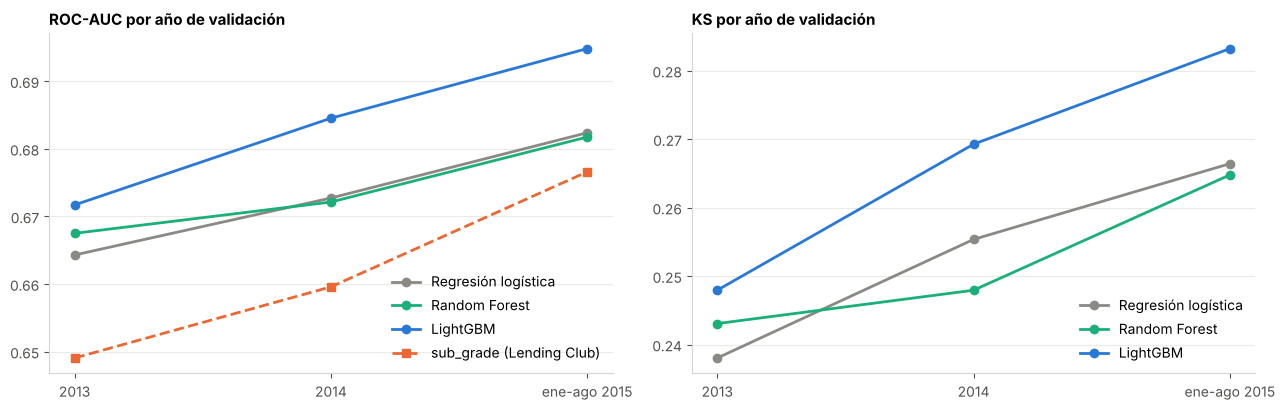

In [11]:
mejores = {'Regresión logística': ('logistica', mejor_logistica),
           'Random Forest': ('random_forest', mejor_rf),
           'LightGBM': ('lightgbm', mejor_lgbm)}

comparacion = pd.DataFrame({
    nombre: mejor[1].mean()[['roc_auc', 'pr_auc', 'ks', 'brier']] for nombre, (_, mejor) in mejores.items()
}).T
comparacion.columns = ['ROC-AUC', 'PR-AUC', 'KS', 'Brier']
comparacion.loc['sub_grade (Lending Club)', 'ROC-AUC'] = benchmark_validacion.mean()
display(comparacion.style.format('{:.4f}', na_rep='-').set_caption('Promedio de los tres años de validación'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
colores = {'Regresión logística': GRIS, 'Random Forest': AQUA, 'LightGBM': AZUL}
for nombre, (_, mejor) in mejores.items():
    axes[0].plot(ANIOS_VALIDACION, mejor[1]['roc_auc'], marker='o', color=colores[nombre], label=nombre)
    axes[1].plot(ANIOS_VALIDACION, mejor[1]['ks'], marker='o', color=colores[nombre], label=nombre)
axes[0].plot(ANIOS_VALIDACION, benchmark_validacion.values, marker='s', linestyle='--',
             color=NARANJA, label='sub_grade (Lending Club)')
axes[0].set_title('ROC-AUC por año de validación')
axes[1].set_title('KS por año de validación')
for ax in axes:
    ax.set_xticks(ANIOS_VALIDACION, ['2013', '2014', 'ene-ago 2015'])
    ax.legend(loc='lower right')
plt.tight_layout()
guardar(fig, '15_comparacion_validacion')
plt.show()

**Qué muestra.**

- **LightGBM es el mejor en los tres años**, en ROC-AUC y en KS, y también tiene el Brier más bajo (probabilidades más precisas). La ventaja sobre la logística es de ~0,01 de AUC y ~0,015 de KS, pareja todos los años.
- **Los tres modelos superan a la nota de Lending Club todos los años.** LightGBM le saca ~0,02 de AUC (0,695 contra 0,677 en 2015), usando solo datos de la persona.
- Random Forest no le gana a la logística: promediar muchos árboles grandes ordena bien, pero no capta mejor las relaciones que la suma ponderada de la logística.
- Todos mejoran año a año, también `sub_grade`. Parte es que cada corte aprende con más datos; parte puede ser que los préstamos más nuevos son más fáciles de ordenar (Lending Club prestó a perfiles más variados, más fáciles de separar).

**Elegimos LightGBM.** Es menos fácil de explicar que la logística, pero lo compensamos con la Sección 6.3, y la logística queda como referencia.

## 5. ¿Qué aportan el desempleo y el estado?

Medimos el aporte con el mismo esquema de validación: entrenamos el LightGBM elegido **sacando** las variables de desempleo, `addr_state`, o ambas, y vemos cuánto cambia. Además miramos si el modelo acierta el **nivel** de default de cada año (la PD promedio contra el default observado), que es donde el ciclo económico debería notarse más.

In [12]:
params_lgbm = mejor_lgbm[0]
variantes = {
    'Completo (con desempleo y estado)': {},
    'Sin desempleo': {'con_macro': False},
    'Sin addr_state': {'con_estado': False},
    'Sin desempleo ni addr_state': {'con_macro': False, 'con_estado': False},
}
resultados_variantes, pd_variantes = {}, {}
for nombre, variante in variantes.items():
    metricas, pd_val = (mejor_lgbm[1], mejor_lgbm[2]) if not variante else validar('lightgbm', params_lgbm, **variante)
    resultados_variantes[nombre] = metricas
    pd_variantes[nombre] = pd_val

tabla_variantes = pd.DataFrame({
    nombre: {**{f'AUC {a}': m.loc[a, 'roc_auc'] for a in ANIOS_VALIDACION},
             'AUC promedio': m['roc_auc'].mean(), 'Brier promedio': m['brier'].mean()}
    for nombre, m in resultados_variantes.items()}).T
tabla_variantes['diferencia de AUC vs. completo'] = tabla_variantes['AUC promedio'] - tabla_variantes.loc[
    'Completo (con desempleo y estado)', 'AUC promedio']
tabla_variantes.round(4)

,AUC 2013,AUC 2014,AUC 2015,AUC promedio,Brier promedio,diferencia de AUC vs. completo
Completo (con desempleo y estado),0.6717,0.6845,0.6948,0.6837,0.1118,0.0000
Sin desempleo,0.6717,0.6845,0.6946,0.6836,0.1118,-0.0001
Sin addr_state,0.6703,0.6839,0.6936,0.6826,0.1119,-0.0011
Sin desempleo ni addr_state,0.6706,0.6840,0.6933,0.6826,0.1119,-0.0010


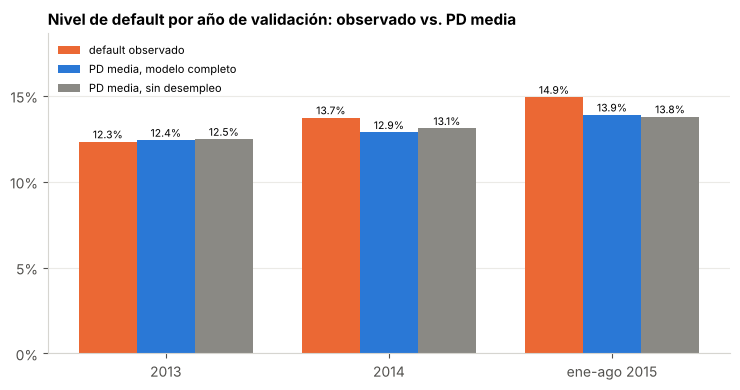

,default observado,"PD media, modelo completo","PD media, sin desempleo"
fecha_originacion,,,
2013,12.33%,12.42%,12.47%
2014,13.73%,12.87%,13.10%
2015,14.92%,13.89%,13.79%


In [13]:
validacion = train.loc[pd_variantes['Completo (con desempleo y estado)'].notna()].copy()
anio_val = validacion['fecha_originacion'].dt.year
nivel = pd.DataFrame({
    'default observado': validacion['default'].groupby(anio_val).mean(),
    'PD media, modelo completo': pd_variantes['Completo (con desempleo y estado)'][validacion.index].groupby(anio_val).mean(),
    'PD media, sin desempleo': pd_variantes['Sin desempleo'][validacion.index].groupby(anio_val).mean(),
})

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(nivel))
for i, (columna, color) in enumerate(zip(nivel.columns, [NARANJA, AZUL, GRIS])):
    barras = ax.bar(x + (i - 1) * 0.26, nivel[columna], width=0.26, color=color, label=columna)
    for b, v in zip(barras, nivel[columna]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f'{v:.1%}', ha='center', fontsize=7.5)
ax.set_xticks(x, ['2013', '2014', 'ene-ago 2015'])
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, nivel.max().max() * 1.25)
ax.set_title('Nivel de default por año de validación: observado vs. PD media')
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
guardar(fig, '16_nivel_por_anio')
plt.show()
nivel.style.format('{:.2%}')

**Qué muestra.**

- **El desempleo no aporta**: sacarlo cambia el AUC en −0,0001, y el Brier no cambia. Aunque varía entre estados, el modelo ya tiene la información relevante en los datos de la persona.
- **Tampoco ayuda a acertar el nivel del default.** El modelo subestima el default en 2014 y 2015 (13,9% contra 14,9% en 2015), y eso pasa con o sin desempleo. Es lo que mostraba la Sección 2.2: el default subió mientras el desempleo bajaba, así que el desempleo no puede explicar esa suba. La suba se debe a algo que no medimos (probablemente, cómo Lending Club fue aflojando su política más allá de lo que se ve en las variables).
- **`addr_state`** aporta poco pero siempre en la misma dirección (+0,001 de AUC en cada uno de los tres años). La dejamos.

**Respuesta a la devolución.** Con estos datos no se puede separar bien el ciclo económico del perfil de los clientes: entre 2009 y 2015 hubo un solo ciclo, y Lending Club cambió su política al mismo tiempo. Para separarlos haría falta una segunda recesión en los datos, o información sobre los préstamos rechazados.

**Decisión: el modelo final no usa las variables de desempleo.** No mejoran nada y obligarían a conseguir un dato externo para cada préstamo nuevo. Quedan disponibles en `src/modelado.py` para el análisis de escenarios de la Entrega 04.

In [14]:
# Decisión de la Sección 5: el modelo final no usa las variables de desempleo
VARIANTE_FINAL = {'con_macro': False}

## 6. Evaluación final con test

Hasta acá todas las decisiones se tomaron con train. Ahora:
1. Volvemos a entrenar cada modelo, con sus hiperparámetros elegidos y sin las variables de desempleo (Sección 5), usando **todo train** (jun-2007 a ago-2015).
2. Predecimos los préstamos de **test** (sep-dic 2015), que no se usaron para nada, y medimos. Es la primera y única vez que miramos el default de test.

### 6.1 Métricas en test

In [15]:
modelos_finales, pd_test = {}, {}
for nombre, (tipo, mejor) in mejores.items():
    inicio = time.time()
    modelos_finales[nombre] = M.crear_modelo(tipo, mejor[0], **VARIANTE_FINAL).fit(train, y_train)
    pd_test[nombre] = M.predecir_pd(modelos_finales[nombre], test)
    print(f'{nombre}: entrenado en {time.time() - inicio:.0f} s')

y_test = test['default']
resultados_test = pd.DataFrame({nombre: E.metricas_pd(y_test, p) for nombre, p in pd_test.items()}).T

# Referencias de Lending Club en los mismos préstamos de test
for nombre, score in [('sub_grade (Lending Club)', test['sub_grade'].rank(method='dense')),
                      ('int_rate (Lending Club)', test['int_rate'])]:
    resultados_test.loc[nombre, ['roc_auc', 'pr_auc', 'ks']] = [
        roc_auc_score(y_test, score), E.average_precision_score(y_test, score), E.ks(y_test, score)]

resultados_test.columns = ['ROC-AUC', 'PR-AUC', 'KS', 'Brier', 'PD media', 'Default observado']
resultados_test.style.format({'ROC-AUC': '{:.4f}', 'PR-AUC': '{:.4f}', 'KS': '{:.4f}', 'Brier': '{:.4f}',
                              'PD media': '{:.1%}', 'Default observado': '{:.1%}'}, na_rep='-')

Regresión logística: entrenado en 11 s


Random Forest: entrenado en 71 s


LightGBM: entrenado en 53 s


,ROC-AUC,PR-AUC,KS,Brier,PD media,Default observado
Regresión logística,0.6910,0.2733,0.2765,0.1189,13.7%,14.8%
Random Forest,0.6903,0.2729,0.2750,0.1196,13.7%,14.8%
LightGBM,0.7044,0.2865,0.2966,0.1177,13.9%,14.8%
sub_grade (Lending Club),0.6826,0.2554,0.2674,-,-,-
int_rate (Lending Club),0.6824,0.2576,0.2676,-,-,-


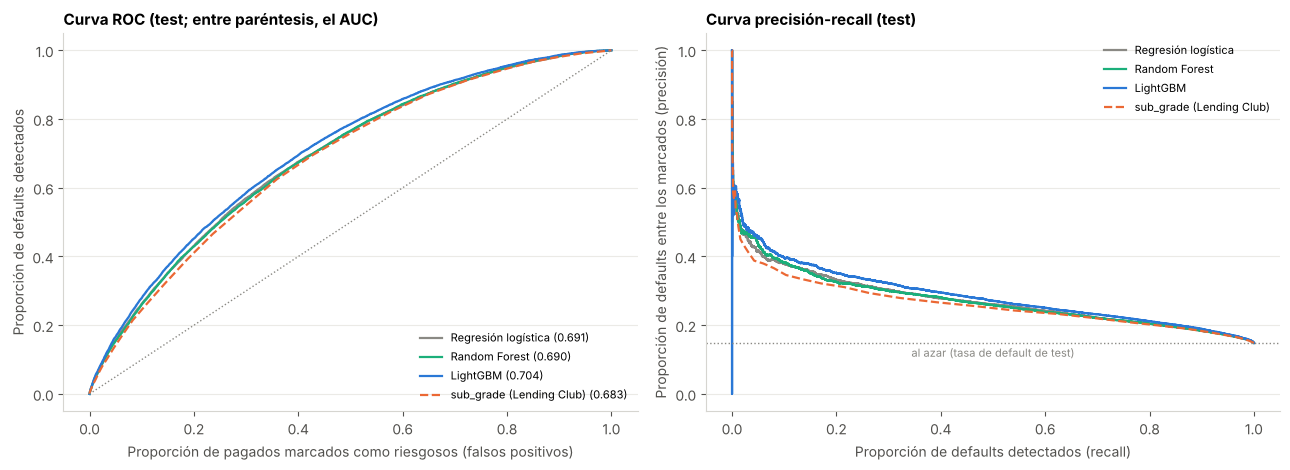

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
curvas = {**{n: p for n, p in pd_test.items()}, 'sub_grade (Lending Club)': test['sub_grade'].rank(method='dense')}
colores_test = {**colores, 'sub_grade (Lending Club)': NARANJA}
for nombre, score in curvas.items():
    estilo = '--' if 'sub_grade' in nombre else '-'
    fpr, tpr, _ = roc_curve(y_test, score)
    axes[0].plot(fpr, tpr, linestyle=estilo, color=colores_test[nombre],
                 label=f"{nombre} ({roc_auc_score(y_test, score):.3f})", linewidth=1.6)
    precision, recall, _ = precision_recall_curve(y_test, score)
    axes[1].plot(recall, precision, linestyle=estilo, color=colores_test[nombre], label=nombre, linewidth=1.6)
axes[0].plot([0, 1], [0, 1], color=GRIS, linewidth=1, linestyle=':')
axes[0].set_xlabel('Proporción de pagados marcados como riesgosos (falsos positivos)')
axes[0].set_ylabel('Proporción de defaults detectados')
axes[0].set_title('Curva ROC (test; entre paréntesis, el AUC)')
axes[0].legend(loc='lower right', fontsize=8)
axes[1].axhline(y_test.mean(), color=GRIS, linewidth=1, linestyle=':')
axes[1].text(0.5, y_test.mean() - 0.04, 'al azar (tasa de default de test)', ha='center', fontsize=8, color=GRIS)
axes[1].set_xlabel('Proporción de defaults detectados (recall)')
axes[1].set_ylabel('Proporción de defaults entre los marcados (precisión)')
axes[1].set_title('Curva precisión-recall (test)')
axes[1].legend(loc='upper right', fontsize=8)
plt.tight_layout()
guardar(fig, '17_curvas_test')
plt.show()

**Qué muestra.**

- **Los resultados de test confirman los de validación**: el orden de los modelos es el mismo y LightGBM vuelve a ganar (AUC 0,704, KS 0,297). Que test dé parecido o algo mejor que el último año de validación (0,695) indica que no elegimos "por suerte" mirando validación.
- **Le ganamos a Lending Club en los mismos préstamos**: `sub_grade` llega a 0,683 de AUC y la tasa de interés a 0,682. Nuestro modelo es mejor en todas las métricas (también en KS: 0,297 contra 0,267).
- En la curva ROC, la línea de LightGBM queda arriba de las demás en todo el recorrido: para cualquier proporción de buenos pagadores que se acepte rechazar, detecta más defaults.
- La curva precisión-recall muestra el límite del problema: entre el 10% de préstamos más riesgosos según el modelo, uno de cada tres cae en default (34%). Con lo que se sabe al pedir el préstamo no se puede anticipar con certeza quién no va a pagar; sí se puede **ordenar el riesgo** y cobrarlo.

### 6.2 ¿Las probabilidades son creíbles? (calibración)

Ordenamos los préstamos de test por PD y los dividimos en 10 grupos del mismo tamaño. Si el modelo está bien calibrado, en cada grupo la PD promedio debería parecerse al default que realmente hubo (los puntos sobre la diagonal).

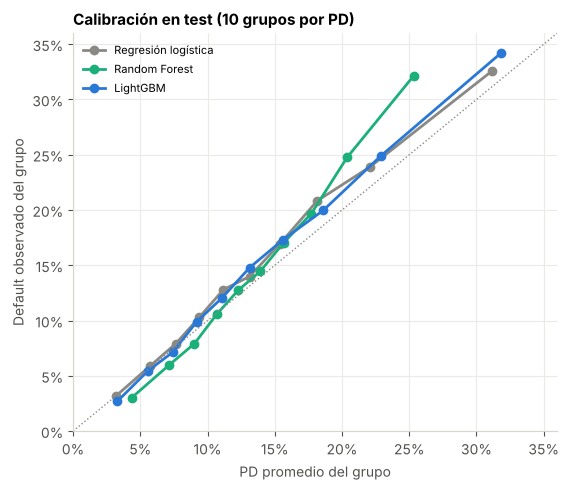

,prestamos,pd_media,default_observado
grupo,,,
1,"10,720",3.3%,2.7%
2,"10,719",5.6%,5.5%
3,"10,720",7.4%,7.1%
4,"10,719",9.2%,9.9%
5,"10,720",11.1%,12.0%
6,"10,719",13.1%,14.8%
7,"10,719",15.6%,17.3%
8,"10,720",18.6%,20.0%
9,"10,719",22.9%,24.9%


In [17]:
MODELO_ELEGIDO = 'LightGBM'
pd_final_test = pd_test[MODELO_ELEGIDO]

fig, ax = plt.subplots(figsize=(5.8, 5))
for nombre in pd_test:
    cal = E.tabla_calibracion(y_test, pd_test[nombre])
    ax.plot(cal['pd_media'], cal['default_observado'], marker='o', color=colores[nombre], label=nombre)
limite = 0.36
ax.plot([0, limite], [0, limite], color=GRIS, linestyle=':', linewidth=1)
ax.set_xlim(0, limite); ax.set_ylim(0, limite)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('PD promedio del grupo'); ax.set_ylabel('Default observado del grupo')
ax.set_title('Calibración en test (10 grupos por PD)')
ax.legend(loc='upper left', fontsize=8)
ax.grid(axis='x')
plt.tight_layout()
guardar(fig, '18_calibracion_test')
plt.show()
E.tabla_calibracion(y_test, pd_final_test).style.format(
    {'prestamos': '{:,}', 'pd_media': '{:.1%}', 'default_observado': '{:.1%}'}).set_caption(MODELO_ELEGIDO)

**Qué muestra.**

- Los puntos siguen la diagonal: cuando el modelo dice más riesgo, hay más default, y en proporciones parecidas. En los grupos de PD baja (3% a 7%) acierta casi exacto.
- Del grupo 4 en adelante el modelo **se queda corto por 1 a 2,5 puntos** (por ejemplo, dice 13,1% y hubo 14,8%). En total, la PD media de test es 13,9% contra 14,8% observado.
- Es la misma subestimación que vimos en validación (Sección 5): el default viene subiendo en 2014-2015 más de lo que explican las variables, y el modelo, que aprendió con todo el período, va un paso atrás. Random Forest está peor calibrado (comprime las PD hacia el medio: subestima arriba y sobreestima abajo).
- **Para la prima de la Entrega 04** conviene corregir este nivel, por ejemplo ajustando la PD con los últimos meses de train. No lo hacemos acá porque esa corrección también hay que validarla sin mirar test.

### 6.3 ¿Qué variables usa más el modelo?

Para el LightGBM mostramos la **importancia por ganancia**: cuánto mejoró el ajuste, sumando todas las veces que el modelo usó esa variable para dividir un árbol. Indica qué variables usa más, no si suben o bajan el riesgo. Para eso mostramos al lado los coeficientes de la regresión logística: como las variables están en la misma escala, un coeficiente positivo y grande significa que esa variable sube mucho la PD.

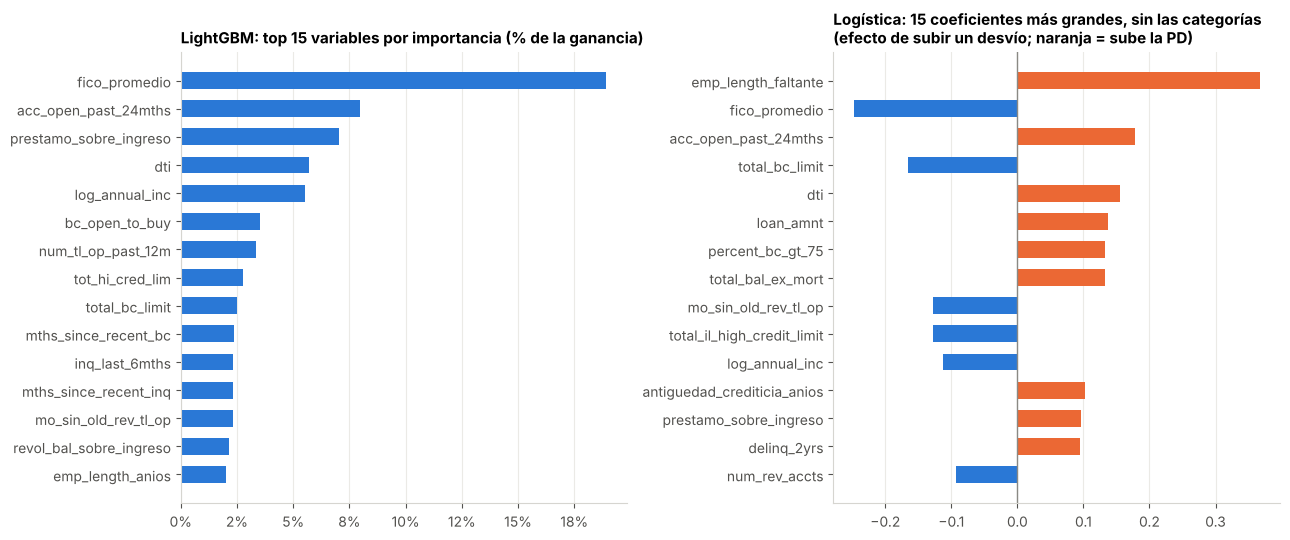

In [18]:
lgbm = modelos_finales['LightGBM'].named_steps['modelo']
nombres = modelos_finales['LightGBM'].named_steps['preprocesamiento'].get_feature_names_out()
importancia = pd.Series(lgbm.booster_.feature_importance('gain'), index=nombres)
importancia = (importancia / importancia.sum()).sort_values().tail(15)

logistica = modelos_finales['Regresión logística']
coeficientes = pd.Series(logistica.named_steps['modelo'].coef_[0],
                         index=logistica.named_steps['preprocesamiento'].get_feature_names_out())
coeficientes = coeficientes[[c for c in coeficientes.index if not c.startswith(tuple(categoricas))]]
top_coef = coeficientes.reindex(coeficientes.abs().sort_values().index).tail(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].barh(importancia.index, importancia.values, color=AZUL, height=0.6)
axes[0].xaxis.set_major_formatter(pct)
axes[0].set_title('LightGBM: top 15 variables por importancia (% de la ganancia)')
axes[1].barh(top_coef.index, top_coef.values, color=[NARANJA if v > 0 else AZUL for v in top_coef.values], height=0.6)
axes[1].axvline(0, color=GRIS, linewidth=1)
axes[1].set_title('Logística: 15 coeficientes más grandes, sin las categorías\n(efecto de subir un desvío; naranja = sube la PD)')
for ax in axes:
    ax.grid(axis='x'); ax.grid(axis='y', visible=False)
plt.tight_layout()
guardar(fig, '19_importancia_variables')
plt.show()

**Qué muestra.**

- El **FICO** es por lejos la variable más usada (~19% de la ganancia), como en la Entrega 02. Le siguen la **cantidad de cuentas abiertas en los últimos 2 años** (`acc_open_past_24mths`, quien abrió muchas cuentas hace poco está tomando más deuda), el **préstamo sobre el ingreso**, el **DTI** y el **ingreso**. Son variables de historial y de capacidad de pago, con sentido económico.
- Varias del historial detallado (`bc_open_to_buy`, `num_tl_op_past_12m`, `total_bc_limit`) están en el top 15: confirma que valió la pena conservarlas aunque falten antes de 2012.
- La logística coincide en las direcciones: **no declarar empleo** sube la PD (es el coeficiente más grande), **más FICO, más límite de tarjetas y más ingreso la bajan**, y **más DTI, más cuentas recientes y más monto la suben**. Algunos coeficientes, como el positivo de la antigüedad crediticia, hay que leerlos con cuidado: esa variable está muy correlacionada con `mo_sin_old_rev_tl_op` (antigüedad de la cuenta de tarjeta más vieja), que tiene el signo contrario, y entre las dos se reparten el efecto.
- Las categorías (que no se muestran a la derecha) dicen lo mismo que en la Entrega 02: `small_business` sube el riesgo; `credit_card` y tener hipoteca o casa propia lo bajan.

## 7. Bandas de riesgo y pérdida esperada

### 7.1 Cómo definimos las bandas

Armamos **7 bandas (1 = menos riesgo, 7 = más riesgo)** con la PD del modelo. Para poder compararlas con las notas de Lending Club, las bandas tienen **el mismo tamaño que las notas A a G**: si el 17% de los préstamos tiene nota A, la banda 1 agrupa al 17% con menor PD, y así.

Los cortes se definen **solo con train**, usando las PD de validación de la Sección 4 (las que el modelo calculó para préstamos que no había visto, 2013 a ago-2015). Después se aplican tal cual a test.

In [19]:
pd_validacion = pd_variantes['Sin desempleo'].dropna()
notas = train.loc[pd_validacion.index, 'grade']
proporcion_nota = notas.value_counts(normalize=True).sort_index()
acumulada = proporcion_nota.cumsum().iloc[:-1]
CORTES_BANDAS = [float(c) for c in pd_validacion.quantile(acumulada.values)]
NOMBRES_BANDAS = [str(i) for i in range(1, 8)]

pd.DataFrame({'nota de LC': proporcion_nota.index,
              '% de préstamos (validación)': proporcion_nota.values,
              'banda': NOMBRES_BANDAS,
              'PD desde': [0] + CORTES_BANDAS,
              'PD hasta': CORTES_BANDAS + [1]}).set_index('banda').style.format(
    {'% de préstamos (validación)': '{:.1%}', 'PD desde': '{:.1%}', 'PD hasta': '{:.1%}'})

,nota de LC,% de préstamos (validación),PD desde,PD hasta
banda,,,,
1,A,21.9%,0.0%,6.7%
2,B,33.6%,6.7%,12.6%
3,C,26.8%,12.6%,20.2%
4,D,13.0%,20.2%,29.1%
5,E,3.8%,29.1%,38.2%
6,F,0.8%,38.2%,48.5%
7,G,0.1%,48.5%,100.0%


### 7.2 Las bandas en test

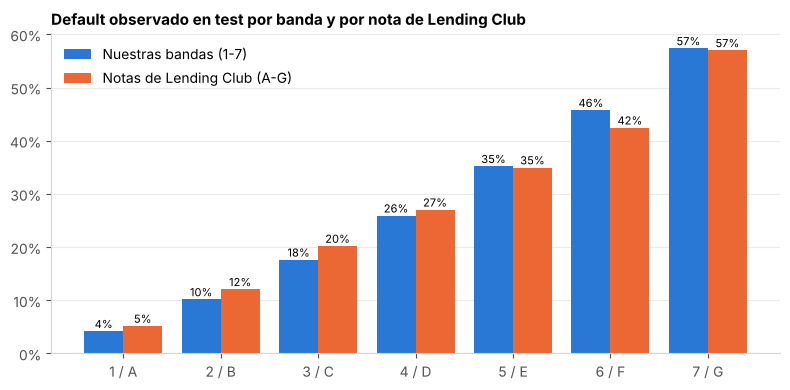

,prestamos,% de prestamos,pd_media,default_observado,perdida_observada,perdida_esperada
banda,,,,,,
1,"22,645",21.1%,4.6%,4.2%,2.0%,2.4%
2,"33,933",31.7%,9.6%,10.2%,5.0%,5.0%
3,"28,610",26.7%,16.0%,17.6%,9.2%,8.3%
4,"15,467",14.4%,24.0%,25.9%,14.1%,12.4%
5,"5,257",4.9%,32.7%,35.2%,20.1%,16.9%
6,"1,154",1.1%,41.6%,45.8%,26.8%,21.5%
7,129,0.1%,52.5%,57.4%,33.9%,27.1%


In [20]:
SEVERIDAD = train.loc[train['default'] == 1, 'perdida_sobre_monto'].mean()
banda_test = E.asignar_banda(pd_final_test, CORTES_BANDAS, NOMBRES_BANDAS)
tabla_bandas = E.tabla_por_banda(banda_test, y_test, pd_final_test,
                                 test['perdida_sobre_monto'], SEVERIDAD)
tabla_notas = test.groupby('grade')['default'].agg(prestamos='size', default_observado='mean')

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(7)
ax.bar(x - 0.2, tabla_bandas['default_observado'], width=0.4, color=AZUL, label='Nuestras bandas (1-7)')
ax.bar(x + 0.2, tabla_notas['default_observado'], width=0.4, color=NARANJA, label='Notas de Lending Club (A-G)')
for i, (a, b) in enumerate(zip(tabla_bandas['default_observado'], tabla_notas['default_observado'])):
    ax.text(i - 0.2, a + 0.006, f'{a:.0%}', ha='center', fontsize=8)
    ax.text(i + 0.2, b + 0.006, f'{b:.0%}', ha='center', fontsize=8)
ax.set_xticks(x, [f'{b} / {n}' for b, n in zip(NOMBRES_BANDAS, tabla_notas.index)])
ax.yaxis.set_major_formatter(pct)
ax.set_title('Default observado en test por banda y por nota de Lending Club')
ax.legend(loc='upper left')
plt.tight_layout()
guardar(fig, '20_bandas_test')
plt.show()

tabla_bandas.style.format({'prestamos': '{:,}', '% de prestamos': '{:.1%}', 'pd_media': '{:.1%}',
                           'default_observado': '{:.1%}', 'perdida_observada': '{:.1%}',
                           'perdida_esperada': '{:.1%}'})

**Qué muestra.**

- **El default sube en todas las bandas**, de 4,2% en la banda 1 a 57,4% en la 7: las bandas ordenan bien el riesgo en préstamos que el modelo nunca vio, con cortes fijados antes de mirar test.
- **La PD media de cada banda se parece al default real**, con la subestimación de 2 a 5 puntos en las bandas altas que ya vimos en la calibración.
- **Contra las notas de Lending Club**: nuestras bandas 1 a 3 tienen menos default que las notas A a C (4% contra 5%, 10% contra 12%, 18% contra 20%). Ojo: la comparación no es exacta, porque en test Lending Club puso más préstamos en A (25%) que nuestra banda 1 (21%). La comparación justa es la del AUC (Sección 6.1).
- **Pérdida esperada contra observada** (las dos como % del monto prestado): en las bandas 1 y 2 coinciden (2,4% contra 2,0%; 5,0% contra 5,0%). Desde la banda 3 la esperada queda abajo, y la diferencia crece: 27% contra 34% en la banda 7. Hay dos motivos: la PD está un poco baja en esas bandas y, sobre todo, **la severidad no es igual para todos**. Dividiendo pérdida observada por default observado, la severidad va de ~48% en la banda 1 a ~59% en la banda 7: los préstamos más riesgosos dejan de pagar antes, cuando todavía deben más capital.
- **Para la prima de la Entrega 04** conviene usar una severidad por banda (estimada en train) en lugar del 51,7% único.

### 7.3 Revisión de la severidad de 2014-2015

La devolución de la Entrega 02 advirtió que en los préstamos de 2014-2015 la cobranza podía no haber terminado cuando se armó el archivo, lo que haría parecer la pérdida **más alta** (falta sumar lo que se iba a recuperar). Comparamos la severidad (pérdida sobre el monto, entre los defaults) por año.

In [21]:
defaults_train = train[train['default'] == 1]
severidad_anual = defaults_train.groupby(defaults_train['fecha_originacion'].dt.year).agg(
    defaults=('perdida_sobre_monto', 'size'),
    severidad=('perdida_sobre_monto', 'mean'),
    lgd=('lgd', 'mean'))
severidad_anual.loc['2007-2013'] = [
    (defaults_train['fecha_originacion'].dt.year <= 2013).sum(),
    defaults_train.loc[defaults_train['fecha_originacion'].dt.year <= 2013, 'perdida_sobre_monto'].mean(),
    defaults_train.loc[defaults_train['fecha_originacion'].dt.year <= 2013, 'lgd'].mean()]
severidad_anual.loc['Todo train'] = [len(defaults_train), SEVERIDAD, defaults_train['lgd'].mean()]
severidad_anual.style.format({'defaults': '{:,.0f}', 'severidad': '{:.1%}', 'lgd': '{:.1%}'})

,defaults,severidad,lgd
fecha_originacion,,,
2007,45,50.0%,88.9%
2008,247,56.9%,91.9%
2009,594,59.0%,92.1%
2010,842,55.2%,92.5%
2011,"1,499",54.8%,91.7%
2012,"5,903",53.6%,90.0%
2013,"12,378",51.3%,88.6%
2014,"22,315",50.7%,88.8%
2015,"26,191",51.8%,89.0%


**Qué muestra.** La severidad de 2014 (50,7%) y 2015 (51,8%) **no es más alta** que la de 2013 (51,3%), ni que el promedio de 2007-2013 (52,6%). El LGD (sobre lo adeudado) también se mantiene en ~89%. Si la cobranza incompleta inflara la pérdida, esos años deberían verse peor, y no pasa.

La razón es la que encontramos en la Entrega 02: en 2014-2015 hay más préstamos sin ningún recupero, pero también más acuerdos de pago, que pierden menos; los dos efectos se compensan. El riesgo de la devolución es real (para los préstamos de test, de fines de 2015, la cobranza tuvo todavía menos tiempo), pero **no cambia la severidad que usamos**: mantenemos 51,7%. Si usáramos solo 2007-2013 daría 52,6%, una diferencia de menos de un punto.

## 8. Guardar y volver a cargar el modelo

Guardamos el modelo elegido en `modelos/` para usarlo en la Entrega 04 **sin volver a entrenar**:

- `modelo_pd.joblib`: el `Pipeline` completo (preparación de las variables + LightGBM). Recibe las columnas tal como están en `train.parquet` (las 54 variables de `features_modelo`) y devuelve la PD. Las columnas que sobran se ignoran.
- `modelo_pd.json`: todo lo demás que hace falta para usarlo y entenderlo: lista de variables, hiperparámetros, cortes de las bandas, severidad, métricas de validación y de test, y versiones de las librerías.

In [22]:
import json, sklearn, lightgbm

numericas_modelo, binarias_modelo, categoricas_modelo = M.columnas_modelo(**VARIANTE_FINAL)
metadatos = {
    'descripcion': 'PD a 36 meses (Charged Off vs Fully Paid), Lending Club, préstamos individuales a 36 meses',
    'modelo': MODELO_ELEGIDO,
    'hiperparametros': params_lgbm,
    'entrenado_con': f"train: {train['fecha_originacion'].min():%Y-%m} a {train['fecha_originacion'].max():%Y-%m}, {len(train):,} préstamos",
    'variables': {'numericas': numericas_modelo, 'binarias': binarias_modelo, 'categoricas': categoricas_modelo},
    'usa_desempleo': VARIANTE_FINAL.get('con_macro', True),
    'bandas': {'nombres': NOMBRES_BANDAS, 'cortes_pd': CORTES_BANDAS},
    'severidad_sobre_monto': SEVERIDAD,
    'metricas_validacion_promedio': resultados_variantes['Sin desempleo'].mean().to_dict(),
    'metricas_test': E.metricas_pd(y_test, pd_final_test),
    'auc_test_sub_grade': resultados_test.loc['sub_grade (Lending Club)', 'ROC-AUC'],
    'versiones': {'python': sys.version.split()[0], 'scikit-learn': sklearn.__version__,
                  'lightgbm': lightgbm.__version__, 'pandas': pd.__version__},
}
ruta = M.guardar_modelo(modelos_finales[MODELO_ELEGIDO], metadatos)
print(f'Guardado: {ruta.relative_to(ruta.parents[1])} ({ruta.stat().st_size / 1e6:.1f} MB)')

Guardado: modelos/modelo_pd.joblib (0.7 MB)


**Prueba de carga.** Cargamos el archivo como si fuera otra sesión, predecimos test de nuevo y verificamos que dé exactamente lo mismo. Después mostramos cómo se usaría con préstamos nuevos: PD, banda y pérdida esperada.

In [23]:
modelo_cargado, meta = M.cargar_modelo()
pd_recargada = M.predecir_pd(modelo_cargado, test)
print('¿Mismas predicciones que antes de guardar?', np.allclose(pd_recargada, pd_final_test))

ejemplo = test.sample(5, random_state=7)
pd_ejemplo = M.predecir_pd(modelo_cargado, ejemplo)
pd.DataFrame({
    'monto': ejemplo['loan_amnt'].values,
    'FICO': ejemplo['fico_promedio'].values,
    'propósito': ejemplo['purpose'].values,
    'estado': ejemplo['addr_state'].values,
    'PD': pd_ejemplo,
    'banda': E.asignar_banda(pd_ejemplo, meta['bandas']['cortes_pd'], meta['bandas']['nombres']),
    'pérdida esperada (% del monto)': pd_ejemplo * meta['severidad_sobre_monto'],
    'nota de LC': ejemplo['sub_grade'].values,
}).style.format({'monto': '{:,.0f}', 'PD': '{:.1%}', 'pérdida esperada (% del monto)': '{:.1%}',
                 }).hide(axis='index')

¿Mismas predicciones que antes de guardar? True


monto,FICO,propósito,estado,PD,banda,pérdida esperada (% del monto),nota de LC
"1,000",692.000000,vacation,OR,6.2%,1,3.2%,D4
"3,000",677.000000,other,MD,25.7%,4,13.3%,F4
"5,000",692.000000,debt_consolidation,MI,6.3%,1,3.2%,B2
"3,000",692.000000,medical,LA,33.6%,5,17.4%,D3
"21,000",717.000000,debt_consolidation,IL,3.7%,1,1.9%,A4


## 9. Reflexión final

### Qué logramos

- Un modelo que **ordena el riesgo mejor que la nota de Lending Club** usando solo datos de la persona: AUC 0,704 contra 0,683 en test, y mejor en cada uno de los tres años de validación. Cumple el objetivo que nos pusimos en la Entrega 01.
- **Bandas de riesgo que funcionan** fuera de la muestra: el default crece de banda en banda, de 4% a 57%.
- Un **modelo guardado** que se carga y predice sin reentrenar, con todo lo necesario (cortes, severidad, variables) para calcular la prima en la Entrega 04.

### Qué tan bueno es, siendo críticos

- **Un AUC de 0,70 es moderado.** Es lo habitual en crédito personal con datos de la solicitud (Lending Club, con su propio modelo, llega a 0,68), pero significa que hay mucha superposición entre buenos y malos pagadores. El modelo sirve para **poner precio** al riesgo, no para predecir con certeza quién no va a pagar.
- **El nivel de la PD queda ~1 punto abajo** en los préstamos más recientes, porque el default venía subiendo en 2014-2015 más de lo que explican las variables. Para la prima eso importa más que el orden.
- **La pérdida esperada con severidad única subestima las bandas riesgosas** (27% contra 34% en la banda 7).
- **El desempleo no ayudó**, y no pudimos separar el ciclo económico del perfil de los clientes: hay un solo ciclo en los datos y coincide con un cambio de política de Lending Club.

### Mejoras posibles

1. **Corregir el nivel de la PD** con los meses más recientes de train (por ejemplo, multiplicar por la razón entre default observado y PD media del último año de validación), validando la corrección sin mirar test. *Para la Entrega 04.*
2. **Severidad por banda** en lugar de un valor único. *Para la Entrega 04.*
3. Probar **otras variables macro** que sí afecten a quien ya tiene el préstamo, como la evolución del desempleo durante la vida del préstamo (para escenarios de estrés, no para predecir al originar).
4. **Ajuste de hiperparámetros más fino** (búsqueda bayesiana, parada temprana): con lo visto en la Sección 4, esperamos ganancias chicas (milésimas de AUC).
5. **Inferencia de rechazados**: el modelo solo vio préstamos aprobados. Para usarlo con todos los que piden haría falta modelar también a los rechazados (Lending Club publica esas solicitudes).

### Qué decidimos y por qué

| Decisión | Por qué |
|---|---|
| Clasificación supervisada con probabilidad (PD) | Necesitamos la probabilidad para bandas y pérdida esperada, no solo el sí/no |
| Métricas: ROC-AUC, PR-AUC, KS, Brier y calibración. Accuracy no | Medimos orden del riesgo y calidad de las probabilidades; con 14% de default, la accuracy engaña |
| Sin rebalancear clases | Rebalancear distorsiona las probabilidades que usamos para la pérdida |
| Logística como base; Random Forest y LightGBM | Un modelo simple y explicable contra dos de árboles que captan no linealidades |
| Validación por año dentro de train (2013, 2014, ene-ago 2015) | Imita el uso real (aprender del pasado, predecir lo nuevo), no toca test y muestra la estabilidad entre años |
| Preprocesamiento dentro de un `Pipeline`, ajustado en cada corte | Ningún paso aprende de los datos con los que se evalúa |
| Pocas combinaciones de hiperparámetros, elegidas por AUC promedio | Las diferencias son chicas; una búsqueda enorme arriesga elegir por suerte |
| Modelo final: **LightGBM** (15 hojas, 1.000 árboles, `learning_rate` 0,02) | Mejor en los tres años de validación y en todas las métricas |
| Desempleo del estado del **mes anterior** (BLS) | Dato que ya existía al dar el préstamo: sin leakage |
| Desempleo **fuera** del modelo final | No mejora (−0,0001 de AUC) y exigiría un dato externo por préstamo |
| `addr_state` se queda | Aporte chico (+0,001 de AUC) pero igual en los tres años |
| Test usado **una sola vez**, al final | Para que el resultado sea una estimación honesta del desempeño futuro |
| 7 bandas del mismo tamaño que las notas A-G, con cortes de validación (train) | Comparables con Lending Club y sin mirar test |
| Severidad 51,7% (sin cambios) | La de 2014-2015 no es más alta que la de años anteriores |
| Modelo guardado como `Pipeline` (.joblib) + metadatos (.json) | Se carga y predice sin reentrenar; el .json documenta cortes, severidad y versiones |